# ۱۵ · Grad-CAM؛ دیدن نواحی مؤثر در پیش‌بینی مدل

در این درس با یک عکس و یک مدل آماده، Grad-CAM را قدم‌به‌قدم می‌سازیم.
هدف این است که ببینیم کدام نواحی تصویر در امتیاز یک کلاس نقش مثبت بیشتری داشته‌اند.
مثال‌ها در TensorFlow و PyTorch اجرا می‌شوند؛ آموزش مدل، دیتاست بزرگ و کتابخانهٔ اضافهٔ توضیح‌پذیری لازم نداریم.
پیش‌نیاز این درس: آشنایی با CNN، گرادیان و تنسورها؛ زمان پیشنهادی تدریس حدود ۴۵ دقیقه است.

**روش مطالعه:** سلول‌ها را از بالا به پایین اجرا کنید. هر بخش یک مفهوم کوچک و یک مثال دارد.
پیش‌نیاز فقط آشنایی مقدماتی با پایتون و لیست است. خروجی‌های فایل از اجرای واقعی کدها ذخیره شده‌اند.
این درس برای اجرا روی CPU نوشته شده است.

<style>
.jp-MarkdownOutput,.text_cell_render {direction:rtl;text-align:right;font-family:Tahoma,Arial,sans-serif;line-height:1.9}
.jp-MarkdownOutput pre,.text_cell_render pre,.jp-CodeCell,.jp-OutputArea-output {direction:ltr;text-align:left}
mjx-container,.MathJax {direction:ltr} table {direction:ltr}
</style>

## ۱. Grad-CAM چیست و چه کاربردی دارد؟

مدل طبقه‌بندی یک نام، مثلاً «اتوبوس»، پیش‌بینی می‌کند. Grad-CAM یک نقشهٔ حرارتی می‌سازد تا
نواحی مرتبط با امتیاز **همان کلاس انتخاب‌شده** را بررسی کنیم.
نام آن مخفف **Gradient-weighted Class Activation Mapping** است.
این روش را Selvaraju و همکاران در پیش‌چاپ ۲۰۱۶ و مقالهٔ ICCV 2017 معرفی کردند.
ایدهٔ آن استفاده از گرادیان امتیاز کلاس برای وزن‌دادن به کانال‌های ویژگی یک لایهٔ کانولوشنی است.

کاربردهای سادهٔ آموزشی:

- بررسی اینکه مدل بیشتر به خود شیء یا به پس‌زمینه وابسته شده است.
- بررسی پیش‌بینی درست و اشتباه، و یافتن سرنخ برای اصلاح داده‌ها.
- مقایسهٔ نقشهٔ دو کلاس روی یک تصویر.

نقشه، **توضیح تقریبی برای مدل** است. مرز دقیق شیء، ماسک segmentation، bounding box یا اثبات علّیِ تصمیم مدل نیست.
رنگ گرم‌تر، مقدار نرمال‌شدهٔ بزرگ‌تر در همین نقشه را نشان می‌دهد؛ رنگ، احتمال کلاس در هر پیکسل نیست.
([مقالهٔ اصلی](https://arxiv.org/abs/1610.02391))

## ۲. فرمول، با معنای هر نماد

فرض کنید خروجی لایهٔ کانولوشنی انتخاب‌شده دارای $K$ کانال و اندازهٔ فضایی $H\times W$ است.
$A^k_{ij}$ مقدار کانال $k$ در مکان $(i,j)$ و $y^c$ امتیاز **پیش از softmax** برای کلاس $c$ است.

ابتدا گرادیان را برای هر کانال روی مکان‌های تصویر میانگین می‌گیریم:

$$\alpha_k^c=\frac{1}{Z}\sum_i\sum_j\frac{\partial y^c}{\partial A^k_{ij}},\qquad Z=H\times W$$

سپس ترکیب وزن‌دار کانال‌ها را می‌سازیم:

$$L^c_{\mathrm{Grad\text{-}CAM}}=\operatorname{ReLU}\left(\sum_k\alpha_k^c A^k\right)$$

**ترجمهٔ کد:** forward → انتخاب امتیاز کلاس → gradient → میانگین گرادیان‌ها → جمع وزن‌دار کانال‌ها → ReLU.
ReLU سهم‌های منفی را حذف می‌کند تا شواهد مثبت برای کلاس نمایش داده شوند.
برای رسم، نقشه را بر بیشینه‌اش تقسیم می‌کنیم و به اندازهٔ ورودی بزرگ می‌کنیم.
اگر تمام مقادیر صفر باشند، نقشه را صفر نگه می‌داریم تا تقسیم بر صفر رخ ندهد.

آخرین ویژگی کانولوشنی معمولاً مفهوم‌های سطح بالاتری دارد، ولی جزئیات مکانی کمتری نگه می‌دارد.
در این مدل نقشهٔ اصلی فقط $7\times7$ است؛ بزرگ‌کردن آن اطلاعات مکانی تازه ایجاد نمی‌کند.
انتخاب logit به‌جای احتمال softmax از وابسته‌شدن گرادیان به اشباع softmax جلوگیری می‌کند.
([مثال رسمی Keras](https://keras.io/examples/vision/grad_cam/))

## ۳. آماده‌سازی محیط

همان requirements.txt مجموعه کافی است. مدل هر کتابخانه وزن ImageNet واقعی دارد؛ اولین دریافت وزن‌ها به اینترنت نیاز دارد.
پس از دریافت، کتابخانه از cache استفاده می‌کند. خروجی‌های ذخیره‌شدهٔ این فایل بدون اجرای دوباره قابل مطالعه‌اند.
در این درس وزن تصادفی را جایگزین وزن pretrained نمی‌کنیم.

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import numpy as np
import tensorflow as tf
import torch
import matplotlib.pyplot as plt

np.random.seed(42)
tf.random.set_seed(42)
torch.manual_seed(42)
torch.set_num_threads(2)

print('NumPy:', np.__version__)
print('TensorFlow:', tf.__version__)
print('PyTorch:', torch.__version__)

C:\Program Files\Python311\Lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.5.0) or chardet (7.6.0)/charset_normalizer (3.4.4) doesn't match a supported version!
  warnings.warn(


NumPy: 2.2.6
TensorFlow: 2.20.0
PyTorch: 2.9.1+cpu


In [2]:
from pathlib import Path
from PIL import Image
from torchvision import transforms
from torchvision.models import mobilenet_v2, MobileNet_V2_Weights
import json

root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
out_dir = root / 'artifacts' / '15_gradcam'
out_dir.mkdir(parents=True, exist_ok=True)

# Standard ImageNet-1K class order, shared by these two classifiers.
weights_pt = MobileNet_V2_Weights.IMAGENET1K_V1
class_names = weights_pt.meta['categories']
print('Number of classes:', len(class_names))

Number of classes: 1000


## ۴. یک عکس، با دو پیش‌پردازش مخصوص وزن‌ها

عکس اتوبوس از دادهٔ همراه درس ۱۳ خوانده می‌شود؛ به اجرای آن درس نیازی نیست.
سمت کوتاه عکس را ۲۵۶ می‌کنیم و برش مرکزی ۲۲۴×۲۲۴ می‌گیریم؛ نسبت تصویر حفظ می‌شود.
تصویر سمت راست دقیقاً همان ناحیه‌ای است که هر دو مدل می‌بینند.
نقشه را هم روی همین برش می‌اندازیم تا مکان‌ها جابه‌جا نشوند.

**TensorFlow MobileNetV2:** RGB در مقیاس ۰ تا ۲۵۵ → preprocess_input → بازهٔ منفی یک تا یک، با ترتیب BHWC.

**Torchvision MobileNetV2:** RGB → ToTensor در بازهٔ صفر تا یک → Normalize با میانگین و انحراف معیار ImageNet، با ترتیب BCHW.
این مسیر همان resize/crop و normalization وزن V1 است.
([پیش‌پردازش وزن Torchvision](https://docs.pytorch.org/vision/0.24/models/generated/torchvision.models.mobilenet_v2.html))

Original PIL size (width, height): (810, 1080)
Display image, HWC: (224, 224, 3)
TensorFlow input, BHWC: (1, 224, 224, 3)
PyTorch input, BCHW: (1, 3, 224, 224)


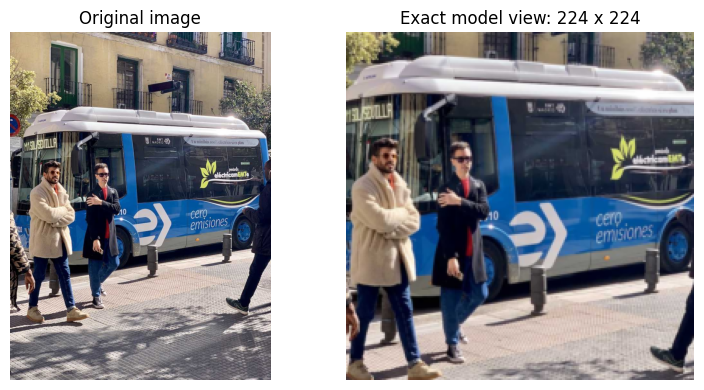

In [3]:
image_path = root / 'data' / 'detection_bus.jpg'
original = Image.open(image_path).convert('RGB')
crop = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
])(original)
image_rgb = np.array(crop)

input_tf = tf.keras.applications.mobilenet_v2.preprocess_input(
    image_rgb[None].astype('float32').copy()
)
normalize_pt = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])
input_pt = normalize_pt(crop).unsqueeze(0)

# Confirm that splitting preprocessing into simple steps matches the preset.
torch.testing.assert_close(input_pt[0], weights_pt.transforms()(original))
print('Original PIL size (width, height):', original.size)
print('Display image, HWC:', image_rgb.shape)
print('TensorFlow input, BHWC:', input_tf.shape)
print('PyTorch input, BCHW:', tuple(input_pt.shape))

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(original); axes[0].set_title('Original image')
axes[1].imshow(image_rgb); axes[1].set_title('Exact model view: 224 x 224')
for ax in axes:
    ax.axis('off')
plt.tight_layout(); plt.show()

## ۵. TensorFlow: مدل و لایهٔ انتخاب‌شده

MobileNetV2 یک CNN سبک است. classifier_activation=None خروجی نهایی را به‌صورت logit نگه می‌دارد.
در این مدل، out_relu ویژگی نهایی کانولوشنی را با اندازهٔ `(B,7,7,1280)` می‌دهد.
پس از آن GlobalAveragePooling و سر ۱۰۰۰کلاسه قرار دارند.
برای خواندن نام‌ها از فهرست استاندارد ImageNet در Torchvision استفاده می‌کنیم؛ اندیس کلاس‌ها در این دو مدل هم‌معناست.
وزن‌های آموزش‌دیدهٔ دو کتابخانه یکسان نیستند، بنابراین الزاماً پیش‌بینی یکسانی ندارند.

In [4]:
model_tf = tf.keras.applications.MobileNetV2(
    weights='imagenet', classifier_activation=None
)
layer_name = 'out_relu'
grad_model_tf = tf.keras.Model(
    model_tf.inputs[0],
    [model_tf.get_layer(layer_name).output, model_tf.output]
)
print('Feature layer:', layer_name)
print('Feature shape:', model_tf.get_layer(layer_name).output.shape)
print('Classifier output:', model_tf.output.shape)

Feature layer: out_relu
Feature shape: (None, 7, 7, 1280)
Classifier output: (None, 1000)


## ۶. TensorFlow: محاسبهٔ مستقیم Grad-CAM

داخل GradientTape خروجی ویژگی و logit را **در یک گراف** محاسبه می‌کنیم.
سپس مشتق امتیاز کلاس نسبت به همان ویژگی را می‌گیریم.
class_index=None یعنی کلاس با بیشترین امتیاز؛ یک عدد صحیح هم می‌تواند کلاس دلخواه را تعیین کند.
این تابع برای یک تصویر در هر فراخوانی نوشته شده است.

training=False رفتار BatchNorm و Dropout را در حالت ارزیابی نگه می‌دارد؛ محاسبهٔ گرادیان همچنان فعال است.
برای Grad-CAM نیازی به optimizer، loss آموزشی، fit یا تغییر وزن‌ها نداریم.

In [5]:
def gradcam_tf(grad_model, image, class_index=None):
    assert image.shape[0] == 1, 'Use one image at a time.'
    with tf.GradientTape() as tape:
        features, logits = grad_model(image, training=False)
        if class_index is None:
            class_index = int(tf.argmax(logits[0]))
        assert 0 <= class_index < logits.shape[-1]
        score = logits[0, class_index]

    gradients = tape.gradient(score, features)
    assert gradients is not None, 'Features must be connected to the score.'
    channel_weights = tf.reduce_mean(gradients, axis=(1, 2), keepdims=True)
    heatmap = tf.reduce_sum(channel_weights * features, axis=-1)[0]
    heatmap = tf.nn.relu(heatmap)
    heatmap = tf.math.divide_no_nan(heatmap, tf.reduce_max(heatmap))

    info = {
        'features': list(features.shape),
        'gradients': list(gradients.shape),
        'channel_weights': list(channel_weights.shape),
        'heatmap': list(heatmap.shape),
        'gradient_norm': float(tf.linalg.global_norm([gradients])),
    }
    return heatmap.numpy(), logits.numpy(), class_index, info

heat_tf, logits_tf, target_tf, info_tf = gradcam_tf(grad_model_tf, input_tf)
prob_tf = tf.nn.softmax(logits_tf, axis=1).numpy()[0]
print('TensorFlow tensor shapes:', info_tf)
print('Top 3 predictions (model probabilities):')
for index in np.argsort(prob_tf)[-3:][::-1]:
    print(f'{index:3d} | {class_names[index]:18s} | {prob_tf[index]:.3f}')

TensorFlow tensor shapes: {'features': [1, 7, 7, 1280], 'gradients': [1, 7, 7, 1280], 'channel_weights': [1, 1, 1, 1280], 'heatmap': [7, 7], 'gradient_norm': 0.22373732924461365}
Top 3 predictions (model probabilities):
654 | minibus            | 0.821
874 | trolleybus         | 0.049
829 | streetcar          | 0.043


## ۷. یک تابع کوچک برای نمایش نقشه

نقشهٔ ۷×۷ را با درون‌یابی bilinear به ۲۲۴×۲۲۴ می‌رسانیم.
در overlay تصویر و رنگ نقشه را با وزن‌های ۰٫۶۵ و ۰٫۳۵ ترکیب می‌کنیم؛ alpha فقط شفافیت رسم را تغییر می‌دهد.
نقشهٔ سمت چپ خام است؛ سمت راست فقط نمایش رنگی آن روی تصویر است.

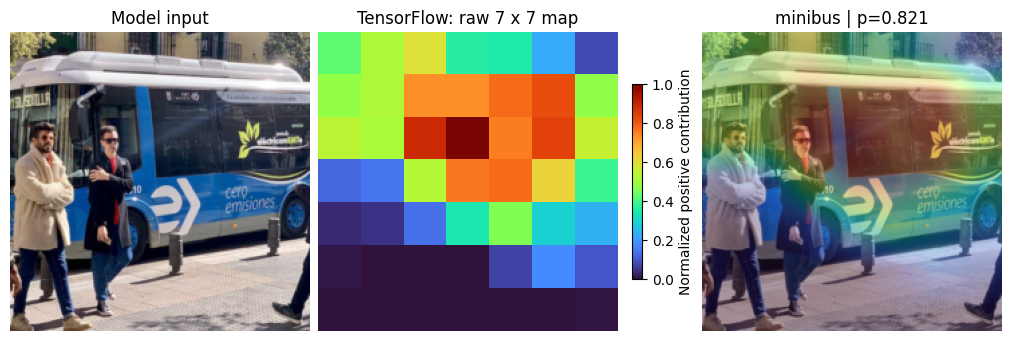

In [6]:
def enlarge_heatmap(heatmap):
    small = Image.fromarray(heatmap.astype('float32'))
    return np.asarray(small.resize(crop.size, Image.Resampling.BILINEAR))

def overlay(heatmap, alpha=0.35):
    large = enlarge_heatmap(heatmap)
    colors = plt.get_cmap('turbo')(large)[..., :3]
    return np.clip((1 - alpha) * image_rgb / 255.0 + alpha * colors, 0, 1)

fig, axes = plt.subplots(1, 3, figsize=(10, 3.3), constrained_layout=True)
axes[0].imshow(image_rgb); axes[0].set_title('Model input')
im = axes[1].imshow(heat_tf, cmap='turbo', vmin=0, vmax=1)
axes[1].set_title('TensorFlow: raw 7 x 7 map')
axes[2].imshow(overlay(heat_tf))
axes[2].set_title(f'{class_names[target_tf]} | p={prob_tf[target_tf]:.3f}')
for ax in axes:
    ax.axis('off')
fig.colorbar(im, ax=axes[1], shrink=0.65, label='Normalized positive contribution')
fig.savefig(out_dir / 'tensorflow_gradcam.png', dpi=140)
plt.show()

## ۸. PyTorch: همان ایده، با محورهای متفاوت

در MobileNetV2 بخش features نقشهٔ کانولوشنی و classifier سر طبقه‌بندی است.
میانگین روی دو محور مکانی، همان global average pooling مدل را می‌سازد.
به همین دلیل این مثال به hook یا کلاس کمکی احتیاج ندارد؛ تابع زیر مخصوص ساختار MobileNetV2 است.
خروجی features این بار `(B,1280,7,7)` است، پس محورهای مکانی ۲ و ۳ هستند.

model.eval() حالت Dropout و BatchNorm را تنظیم می‌کند و گرادیان را غیرفعال نمی‌کند.
**دور محاسبهٔ Grad-CAM از no_grad یا inference_mode استفاده نمی‌کنیم.**
autograd.grad مشتق موردنیاز را برمی‌گرداند؛ optimizer و به‌روزرسانی وزن نداریم.
([راهنمای autograd.grad](https://docs.pytorch.org/docs/2.9/generated/torch.autograd.grad.html))

In [7]:
model_pt = mobilenet_v2(weights=weights_pt).eval()

def gradcam_pt(model, image, class_index=None):
    assert image.shape[0] == 1, 'Use one image at a time.'
    features = model.features(image)
    pooled = features.mean(dim=(2, 3))
    logits = model.classifier(pooled)
    if class_index is None:
        class_index = int(logits[0].argmax())
    assert 0 <= class_index < logits.shape[-1]
    score = logits[0, class_index]

    gradients = torch.autograd.grad(score, features)[0]
    channel_weights = gradients.mean(dim=(2, 3), keepdim=True)
    heatmap = (channel_weights * features).sum(dim=1)[0].clamp(min=0)
    heatmap = heatmap / heatmap.max().clamp(min=1e-12)

    info = {
        'features': list(features.shape),
        'gradients': list(gradients.shape),
        'channel_weights': list(channel_weights.shape),
        'heatmap': list(heatmap.shape),
        'gradient_norm': float(gradients.norm()),
    }
    return heatmap.detach().numpy(), logits.detach().numpy(), class_index, info

heat_pt, logits_pt, target_pt, info_pt = gradcam_pt(model_pt, input_pt)
prob_pt = torch.softmax(torch.from_numpy(logits_pt), dim=1).numpy()[0]

# Check that our explicit pooling + head is the model's actual forward path.
with torch.no_grad():
    direct_logits = model_pt(input_pt).numpy()
np.testing.assert_allclose(logits_pt, direct_logits, rtol=1e-4, atol=1e-5)
print('PyTorch tensor shapes:', info_pt)
print('Top 3 predictions (model probabilities):')
for index in np.argsort(prob_pt)[-3:][::-1]:
    print(f'{index:3d} | {class_names[index]:18s} | {prob_pt[index]:.3f}')

PyTorch tensor shapes: {'features': [1, 1280, 7, 7], 'gradients': [1, 1280, 7, 7], 'channel_weights': [1, 1280, 1, 1], 'heatmap': [7, 7], 'gradient_norm': 0.2689708471298218}
Top 3 predictions (model probabilities):
654 | minibus            | 0.466
734 | police van         | 0.445
757 | recreational vehicle | 0.054


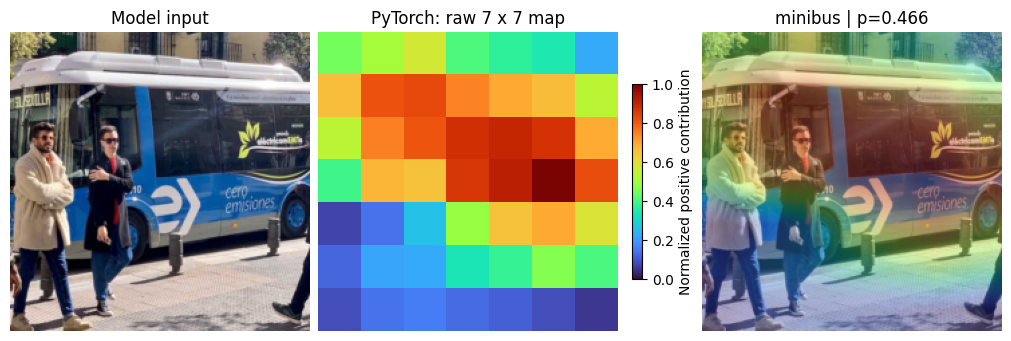

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.3), constrained_layout=True)
axes[0].imshow(image_rgb); axes[0].set_title('Model input')
im = axes[1].imshow(heat_pt, cmap='turbo', vmin=0, vmax=1)
axes[1].set_title('PyTorch: raw 7 x 7 map')
axes[2].imshow(overlay(heat_pt))
axes[2].set_title(f'{class_names[target_pt]} | p={prob_pt[target_pt]:.3f}')
for ax in axes:
    ax.axis('off')
fig.colorbar(im, ax=axes[1], shrink=0.65, label='Normalized positive contribution')
fig.savefig(out_dir / 'pytorch_gradcam.png', dpi=140)
plt.show()

## ۹. تغییر کلاس هدف؛ مدل و تصویر ثابت‌اند

برای دیدن وابستگی نقشه به کلاس، در هر کتابخانه کلاس اول و دومِ پیش‌بینی‌شده را رسم می‌کنیم.
با عوض‌شدن class_index فقط امتیازی که مشتق می‌گیریم عوض می‌شود؛ تصویر و وزن‌های مدل همان‌اند.
عدد کنار نام کلاس احتمال softmax برای کل تصویر است و در فرمول گرادیان استفاده نمی‌شود.
اگر دو نام مرتبط باشند، شباهت نقشه‌ها طبیعی است؛ لازم نیست هر دو کلاس نقشه‌ای کاملاً متفاوت داشته باشند.

برای انتخاب یک کلاس دلخواه، در فراخوانی تابع به‌جای None اندیس آن را بدهید؛ مثلاً
`class_index=target_tf` برای همان کلاس منتخب TensorFlow. اندیس‌ها از صفر شروع می‌شوند.

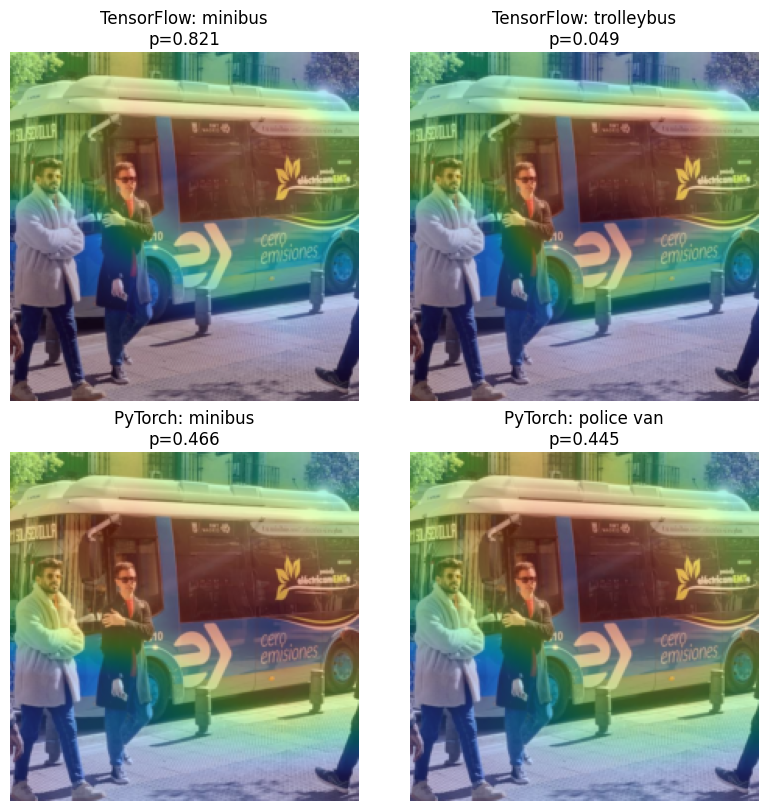

In [9]:
second_tf = int(np.argsort(prob_tf)[-2])
second_pt = int(np.argsort(prob_pt)[-2])
heat_tf_second, _, _, _ = gradcam_tf(grad_model_tf, input_tf, class_index=second_tf)
heat_pt_second, _, _, _ = gradcam_pt(model_pt, input_pt, class_index=second_pt)

examples = [
    ('TensorFlow', heat_tf, target_tf, prob_tf),
    ('TensorFlow', heat_tf_second, second_tf, prob_tf),
    ('PyTorch', heat_pt, target_pt, prob_pt),
    ('PyTorch', heat_pt_second, second_pt, prob_pt),
]
fig, axes = plt.subplots(2, 2, figsize=(8, 8), constrained_layout=True)
for ax, (name, heat, target, probabilities) in zip(axes.flat, examples):
    ax.imshow(overlay(heat))
    ax.set_title(f'{name}: {class_names[target]}\np={probabilities[target]:.3f}')
    ax.axis('off')
fig.savefig(out_dir / 'target_class_comparison.png', dpi=140)
plt.show()

## ۱۰. چطور نتیجه را بخوانیم؟

ابتدا نام پیش‌بینی‌شده و سپس ناحیهٔ گرم را بررسی کنید. آیا آن ناحیه روی اتوبوس است؟
آیا بخشی از افراد، جاده یا پس‌زمینه هم مقدار بالا گرفته است؟ پاسخ را از **خروجی واقعی بالا** بخوانید.
این عکس چند شیء دارد؛ طبقه‌بند ImageNet قرار نیست برای تمام آن‌ها کادر جدا بسازد.

هر نقشه جداگانه به بازهٔ صفر تا یک برده شده است. پس قرمز بودن دو نقشه به معنی برابری
قدرت شواهد یا اعتماد دو مدل نیست. وزن‌ها و normalization دو مدل هم متفاوت‌اند؛ این مقایسه benchmark برتری مدل‌ها نیست.
حتی برای کلاس با احتمال کم ممکن است نقشهٔ رنگی پررنگی ببینیم، چون مقیاس نقشه نسبی است.
نقشهٔ تمام‌صفر هم ممکن است رخ دهد: شواهد مثبت در لایهٔ انتخابی پیدا نشده است.

در یک لایهٔ زودتر، نقشه معمولاً ریزتر و الگوها کم‌معناترند؛ در لایهٔ آخر، الگوها معنایی‌تر و نقشه درشت‌تر است.
برای این درس همان لایهٔ آخر را نگه می‌داریم.

## ۱۱. خطاهای رایج و استفاده برای مدل خودتان

- **نقشه جابه‌جاست:** آن را روی همان resize/crop ورودی مدل رسم کنید.
- **گرادیان None است:** خروجی ویژگی و امتیاز باید به هم متصل باشند؛ در TensorFlow داخل همان GradientTape محاسبه شوند.
- **PyTorch گرادیان ندارد:** eval مشکلی ندارد، ولی no_grad و detach قبل از محاسبهٔ امتیاز، مسیر مشتق را قطع می‌کنند.
  در این مثال پارامترهای مدل requires_grad=True دارند؛ تابع برای مدل کاملاً freeze‌شده بدون اصلاح مسیر گرادیان نوشته نشده است.
- **انتخاب softmax یا کلاس اشتباه:** گرادیان logit همان کلاس موردنظر را بگیرید؛ logit احتمال نیست.

برای مدل شخصی، preprocessing زمان آموزش و ترتیب class_names خودتان را نگه دارید.
در TensorFlow نام لایهٔ ویژگی کانولوشنی و مدل دوخروجی را تغییر دهید.
در PyTorch مسیر features → pooling → classifier را مطابق معماری خودتان بنویسید؛ این تقسیم مخصوص MobileNetV2 است.
برای مدل پنج‌کلاسهٔ درس ۱۴، شمارهٔ کلاس بین صفر و چهار است و نام‌ها نام گل‌ها هستند، نه فهرست ImageNet.
اگر backbone تو‌در‌تو باشد، مدل دوخروجی باید از همان گراف ورودی به ویژگی و سر آموزش‌دیده متصل شود؛ صرفاً تغییر نام لایه کافی نیست.

## ۱۲. ذخیرهٔ نتیجه و کنترل ساده

اندازهٔ نقشه و متناهی‌بودن مقادیر و غیرصفر بودن گرادیان را کنترل می‌کنیم.
این کنترل، درست‌بودن معناییِ توضیح را اثبات نمی‌کند؛ فقط از سالم‌بودن محاسبه در این مثال اطمینان می‌دهد.
نقشه‌های عددی و سه تصویر خروجی در artifacts/15_gradcam ذخیره می‌شوند.

In [10]:
for name, heat, info in [('TensorFlow', heat_tf, info_tf), ('PyTorch', heat_pt, info_pt)]:
    assert heat.shape == (7, 7)
    assert np.isfinite(heat).all()
    assert 0 <= float(heat.min()) <= float(heat.max()) <= 1.000001
    assert info['gradient_norm'] > 0
    print(f'{name}: heatmap={heat.shape}, range=[{heat.min():.3f}, {heat.max():.3f}], gradients OK')

np.savez(out_dir / 'heatmaps.npz', tensorflow=heat_tf, pytorch=heat_pt,
         tensorflow_second=heat_tf_second, pytorch_second=heat_pt_second)
results = {
    'model': 'MobileNetV2', 'image': 'data/detection_bus.jpg',
    'input_size': [224, 224], 'heatmap_size': [7, 7],
    'target_score': 'pre-softmax logit',
    'tensorflow': {'class_index': target_tf, 'class_name': class_names[target_tf],
                   'probability': float(prob_tf[target_tf]), **info_tf},
    'pytorch': {'class_index': target_pt, 'class_name': class_names[target_pt],
                'probability': float(prob_pt[target_pt]), **info_pt},
}
(out_dir / 'results.json').write_text(json.dumps(results, indent=2), encoding='utf-8')
print('Saved to:', out_dir)

TensorFlow: heatmap=(7, 7), range=[0.000, 1.000], gradients OK
PyTorch: heatmap=(7, 7), range=[0.053, 1.000], gradients OK
Saved to: C:\Users\Ahmad\Desktop\deep\artifacts\15_gradcam


## تمرین کوتاه برای کلاس

۱. عکس را با یک عکس دیگر جایگزین کنید و همهٔ سلول‌ها را از نو اجرا کنید. نام سه پیش‌بینی و محل ناحیهٔ گرم را توضیح دهید.

۲. اندیس کلاس دوم را به تابع بدهید؛ کدام قسمت نقشه عوض شد؟ احتمال کم را با رنگ قرمز اشتباه نگیرید.

۳. alpha در تابع overlay را از ۰٫۳۵ به ۰٫۶ تغییر دهید. فقط نمایش عوض می‌شود یا مقادیر اصلی heatmap هم تغییر می‌کنند؟

**پاسخ تمرین ۳:** فقط نمایش عوض می‌شود؛ alpha در فرمول Grad-CAM وارد نشده است.

## منابع رسمی

- [مقالهٔ اصلی Grad-CAM؛ Selvaraju و همکاران](https://arxiv.org/abs/1610.02391)
- [مثال رسمی Grad-CAM در Keras](https://keras.io/examples/vision/grad_cam/)
- [MobileNetV2 و preprocessing در Keras](https://keras.io/api/applications/mobilenet/)
- [MobileNetV2 و وزن‌های V1 در Torchvision 0.24](https://docs.pytorch.org/vision/0.24/models/generated/torchvision.models.mobilenet_v2.html)
- [torch.autograd.grad در PyTorch 2.9](https://docs.pytorch.org/docs/2.9/generated/torch.autograd.grad.html)
- [منبع تصویر نمونهٔ اتوبوس](https://github.com/ultralytics/ultralytics/tree/main/ultralytics/assets)

کدها برای تدریسِ مسیر محاسبه نوشته شده‌اند؛ وابستگی به بستهٔ جانبی Grad-CAM ندارند.
نام محورهای نمودار انگلیسی است تا بدون نیاز به فونت یا ابزار شکل‌دهی فارسی نمایش داده شوند.

بازبینی منابع و اجرای این درس: ۱۶ اکتبر ۲۰۲۶.